# Lab 5: Airline Passenger Satisfaction Prediction with a Neural Network

**Zhan Tabuldinov, BDA-2401**

The recommended topic was employee attrition. The task allows any other classification problem where a neural network can be used, so I chose **airline passenger satisfaction**: predict from the flight details and service ratings whether a passenger is satisfied or not. The dataset is large (about 130 000 passengers), which is what a neural network needs; on the small employee attrition dataset (1 470 rows) a neural network gives no gain over a simple model.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os; os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, time
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
sns.set_theme(style="whitegrid")
tf.random.set_seed(42); np.random.seed(42); tf.config.experimental.enable_op_determinism()
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.15.1


## 1. Dataset Selection

**Dataset:** Airline Passenger Satisfaction (Klein, 2020), published on Kaggle, license "Other (specified in description)" – free for educational use.
**Link:** https://www.kaggle.com/datasets/teejmahal20/airline-passenger-satisfaction

**Why it is relevant to my major:** airlines collect surveys from every flight and have millions of records. Big Data Analytics turns them into models that tell which service factors really drive satisfaction and which passengers are at risk of leaving to a competitor – the same "customer churn" logic as in Lab 2.

* **Target:** `satisfaction` – "satisfied" (1) or "neutral or dissatisfied" (0). Binary classification.
* **Input features (22):** passenger profile (gender, loyal / disloyal customer, age, type of travel, class), flight (distance, departure and arrival delay in minutes) and 14 service ratings on a 0–5 scale (wifi, online booking, seat comfort, food, entertainment, leg room, baggage, check-in, cleanliness, …).
* **Observations:** 129 880 passengers (the author gives `train.csv` with 103 904 rows and `test.csv` with 25 976 rows; I join them and make my own split), 25 columns = 22 features + target + 2 index columns.

In [2]:
import kagglehub
path = kagglehub.dataset_download("teejmahal20/airline-passenger-satisfaction")
df = pd.concat([pd.read_csv(path + "/train.csv"), pd.read_csv(path + "/test.csv")], ignore_index=True)
print(df.shape)
df.head()

(129880, 25)


,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


## 2. Business Understanding

* **Problem.** An airline knows the satisfaction of a passenger only if the passenger fills in a survey (a few percent of all flights). For the other passengers the airline does not know who is unhappy until they stop flying with it.
* **What the model predicts.** For every passenger and flight – whether the passenger is satisfied, using the ticket data (class, distance, delay) and the ratings that are available.
* **Who will use it.** The customer experience team (which service to fix first), marketing and loyalty programme (whom to send an apology or a bonus after a bad flight), operations (how much a delay really costs in satisfaction).
* **How it helps.** The model shows which factors move satisfaction the most (for example online boarding or wifi), so the airline can spend the budget on the right service. Predicting unhappy passengers lets the airline react before they leave – a retained frequent flyer is worth thousands of dollars per year.

**Success criteria (defined before modelling), on the test set:**

| Metric | Threshold | Reason |
|---|---|---|
| Accuracy | ≥ 0.90 | must be clearly better than the naive model "everybody is dissatisfied" (57 %) and than a simple linear model (≈ 0.89, see Section 8) |
| Recall (satisfied class) | ≥ 0.90 | we must recognise most of the satisfied passengers correctly, otherwise the airline will send apologies to happy clients |
| F1-score | ≥ 0.90 | precision and recall must both be high |

The most important metric is **F1** (the classes are almost balanced, 43 % vs 57 %, and both types of errors cost money).

**Short glossary** (definitions follow Géron, 2019, chs. 3 and 10). *Neural network* – a model built from layers of simple units (neurons); each neuron computes a weighted sum of its inputs and passes it through an activation function. *Dense layer* – a layer where every neuron is connected to every input. *ReLU* – activation max(0, x) for hidden layers. *Sigmoid* – activation that squeezes any number into (0, 1), used as the output for binary classification. *Epoch* – one pass through the whole training set. *Batch size* – number of rows the network sees before one weight update. *Learning rate* – the size of one weight update step. *Loss (cost) function* – a number that measures how wrong the predictions are; for binary classification it is *binary cross-entropy*. *Accuracy, precision, recall, F1, confusion matrix* – see Lab 2 (Géron, 2019, ch. 3). All preprocessing is done with scikit-learn (Pedregosa et al., 2011) and the network with Keras / TensorFlow (Chollet, 2015; Abadi et al., 2016).

## 3. Exploratory Data Analysis

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 25 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Unnamed: 0                         129880 non-null  int64  
 1   id                                 129880 non-null  int64  
 2   Gender                             129880 non-null  object 
 3   Customer Type                      129880 non-null  object 
 4   Age                                129880 non-null  int64  
 5   Type of Travel                     129880 non-null  object 
 6   Class                              129880 non-null  object 
 7   Flight Distance                    129880 non-null  int64  
 8   Inflight wifi service              129880 non-null  int64  
 9   Departure/Arrival time convenient  129880 non-null  int64  
 10  Ease of Online booking             129880 non-null  int64  
 11  Gate location                      1298

In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,129880.0,44158.70,31207.38,0.0,16234.75,38963.5,71433.25,103903.0
id,129880.0,64940.50,37493.27,1.0,32470.75,64940.5,97410.25,129880.0
Age,129880.0,39.43,15.12,7.0,27.00,40.0,51.00,85.0
Flight Distance,129880.0,1190.32,997.45,31.0,414.00,844.0,1744.00,4983.0
Inflight wifi service,129880.0,2.73,1.33,0.0,2.00,3.0,4.00,5.0
Departure/Arrival time convenient,129880.0,3.06,1.53,0.0,2.00,3.0,4.00,5.0
Ease of Online booking,129880.0,2.76,1.40,0.0,2.00,3.0,4.00,5.0
Gate location,129880.0,2.98,1.28,0.0,2.00,3.0,4.00,5.0
Food and drink,129880.0,3.20,1.33,0.0,2.00,3.0,4.00,5.0
Online boarding,129880.0,3.25,1.35,0.0,2.00,3.0,4.00,5.0


129 880 rows, 25 columns. Four text columns (gender, customer type, type of travel, class) and the target; all other columns are numeric. `Unnamed: 0` and `id` are index columns without information. `Arrival Delay in Minutes` has 393 missing values.

Some facts: passengers are 7–85 years old (median 40), flights are 31–4 983 miles (median 844), the median delay is 0 minutes but the maximum is 1 592 (26 hours). The 14 service ratings are on a 0–5 scale with means between 2.7 and 3.6; **0 means "not applicable"** (for example wifi rating on a plane without wifi), not the worst grade.

satisfaction
neutral or dissatisfied    0.566
satisfied                  0.434
Name: proportion, dtype: float64


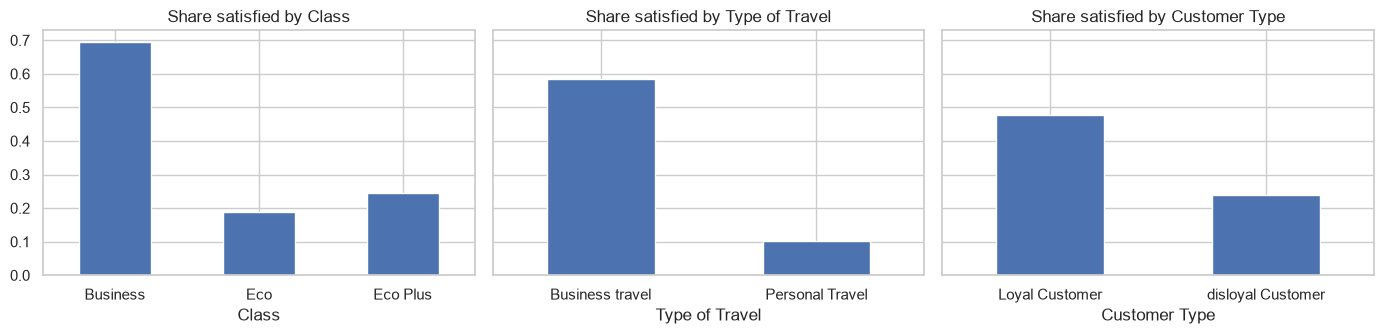

In [5]:
print(df["satisfaction"].value_counts(normalize=True).round(3))
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for a, c in zip(ax, ["Class", "Type of Travel", "Customer Type"]):
    df.groupby(c)["satisfaction"].apply(lambda s: (s == "satisfied").mean()).plot.bar(ax=a, color="#4C72B0", rot=0, title=f"Share satisfied by {c}")
plt.tight_layout(); plt.show()

**Figure 1.** 43 % of passengers are satisfied, 57 % neutral or dissatisfied – the classes are almost balanced. Business class passengers are satisfied in 69 % of cases, economy only in 19 %. Business travellers (58 %) are much happier than personal travellers (10 %), and loyal customers (48 %) happier than disloyal ones (24 %).

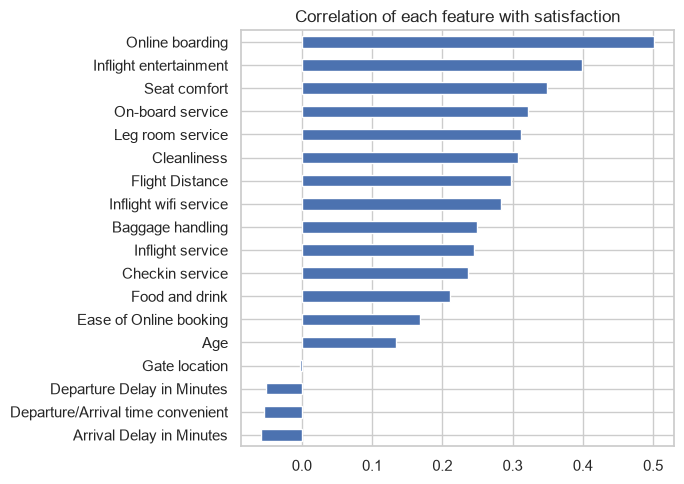

In [6]:
services = ["Inflight wifi service", "Departure/Arrival time convenient", "Ease of Online booking", "Gate location", "Food and drink",
            "Online boarding", "Seat comfort", "Inflight entertainment", "On-board service", "Leg room service", "Baggage handling",
            "Checkin service", "Inflight service", "Cleanliness"]
df["y"] = (df["satisfaction"] == "satisfied").astype(int)
corr = df[services + ["Age", "Flight Distance", "Departure Delay in Minutes", "Arrival Delay in Minutes", "y"]].corr()["y"].drop("y").sort_values()
plt.figure(figsize=(7, 5))
corr.plot.barh(color="#4C72B0"); plt.title("Correlation of each feature with satisfaction"); plt.tight_layout(); plt.show()

**Figure 2.** The strongest single factors are online boarding (0.50), inflight entertainment (0.40), seat comfort (0.35) and on-board service (0.32). Delays have almost no linear correlation (−0.05) and gate location none at all. No single feature is decisive – satisfaction is a combination of many ratings, which is a good case for a neural network.

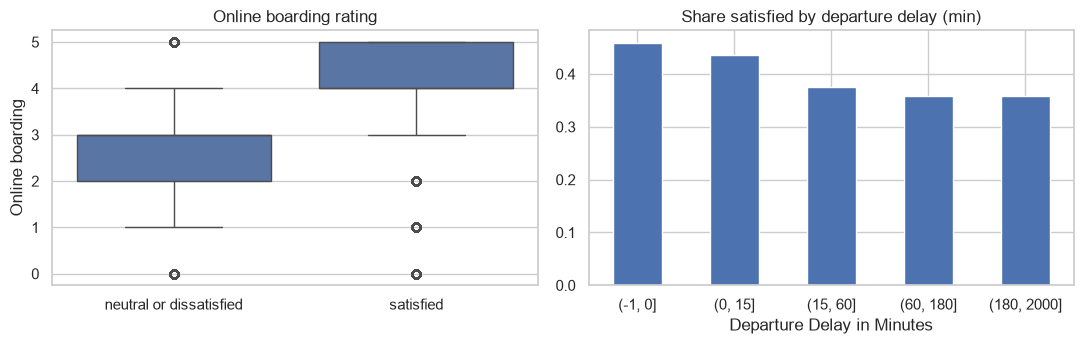

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
sns.boxplot(data=df, x="satisfaction", y="Online boarding", color="#4C72B0", ax=ax[0]).set(title="Online boarding rating", xlabel="")
df.groupby(pd.cut(df["Departure Delay in Minutes"], [-1, 0, 15, 60, 180, 2000]))["y"].mean().plot.bar(ax=ax[1], color="#4C72B0", rot=0, title="Share satisfied by departure delay (min)")
plt.tight_layout(); plt.show()

**Figure 3.** Satisfied passengers rate online boarding 4–5, dissatisfied ones 2–3 – the clearest single split in the data. Delay matters, but not linearly: the share of satisfied passengers is 45 % without delay and drops to 34 % only for delays over 3 hours; short delays (up to 15 minutes) change nothing.

## 4. Data Cleaning

In [8]:
print("missing:", df.isna().sum()[df.isna().sum() > 0].to_dict())
print("duplicate rows (without id):", df.drop(columns=["Unnamed: 0", "id"]).duplicated().sum(), "| duplicate ids:", df["id"].duplicated().sum())
print("ratings outside 0-5:", int((df[services] > 5).sum().sum() + (df[services] < 0).sum().sum()))
print("age outside 0-100:", (~df["Age"].between(0, 100)).sum(), "| negative delays:", ((df["Departure Delay in Minutes"] < 0) | (df["Arrival Delay in Minutes"] < 0)).sum())
print("delay > 6 hours:", (df["Departure Delay in Minutes"] > 360).sum())
print("zero ('not applicable') ratings per column:", {c: int((df[c] == 0).sum()) for c in services if (df[c] == 0).sum() > 100})

missing: {'Arrival Delay in Minutes': 393}
duplicate rows (without id): 0 | duplicate ids: 0
ratings outside 0-5: 0
age outside 0-100: 0 | negative delays: 0
delay > 6 hours: 150
zero ('not applicable') ratings per column: {'Inflight wifi service': 3916, 'Departure/Arrival time convenient': 6681, 'Ease of Online booking': 5682, 'Food and drink': 132, 'Online boarding': 3080, 'Leg room service': 598}


In [9]:
before = df.shape
df = df.drop(columns=["Unnamed: 0", "id", "satisfaction"])
df["Arrival Delay in Minutes"] = df["Arrival Delay in Minutes"].fillna(df["Departure Delay in Minutes"])
print("shape before:", before, "-> after:", df.shape, "| missing now:", df.isna().sum().sum())

shape before: (129880, 26) -> after: (129880, 23) | missing now: 0


**What was done (129 880 × 25 → 129 880 × 23).**

* **Missing values:** 393 arrival delays are missing. Arrival delay is almost the same as departure delay (correlation 0.96), so the missing values are filled with the departure delay of the same flight – better than a global median.
* **Duplicates:** none (no duplicate rows and no duplicate passenger ids).
* **Data types:** correct; the target text column is replaced by the numeric `y`; index columns `Unnamed: 0` and `id` are dropped.
* **Invalid values:** none – all ratings are inside 0–5, ages inside 7–85, no negative delays.
* **Outliers:** 150 flights with a delay over 6 hours are real events (cancellations and re-bookings), they are kept; the scaler and the network handle them. Zero ratings mean "not applicable" (3 000–6 700 zeros for wifi, online booking and time convenience) and are kept as they are; a separate feature counts them (Section 5).

## 5. Feature Engineering

**Created features**

| Feature | Formula | How it helps the network |
|---|---|---|
| `avg_service` | mean of the 14 ratings, zeros ("not applicable") ignored | one compact "overall service" number; correlation with the target 0.53 – higher than any single rating; gives the network a strong direct signal so it can spend its capacity on the interactions |
| `total_delay` | departure + arrival delay | one delay number instead of two almost identical ones |
| `n_zero_ratings` | number of ratings equal to 0 | tells the network that a 0 is "not applicable", not "terrible"; without it the network would read a zero as the worst grade |

**Kept:** all 14 ratings (the network can learn which ones matter), age, flight distance, the four categorical columns.

**Removed:** `Unnamed: 0` and `id` (index columns, no information; a network could only memorise them) – already dropped in cleaning. Nothing else is removed: with 130 000 rows and 25 inputs the network is not in danger of over-fitting because of too many features.

In [10]:
df["avg_service"] = df[services].replace(0, np.nan).mean(axis=1).fillna(0)
df["total_delay"] = df["Departure Delay in Minutes"] + df["Arrival Delay in Minutes"]
df["n_zero_ratings"] = (df[services] == 0).sum(axis=1)
print(df[["avg_service", "total_delay", "n_zero_ratings", "y"]].corr()["y"].round(2))
print(df.shape)

avg_service       0.53
total_delay      -0.05
n_zero_ratings    0.11
y                 1.00
Name: y, dtype: float64
(129880, 26)


## 6. Data Preprocessing

* X = 25 features, y = `y`. First split 80 / 20 into train and **test** (stratified, `random_state=42`); then 20 % of the training part is kept as a **validation set** to watch the loss during training and to stop early. The test set is used only once, in Section 8.
* Categories → OneHotEncoder (binary columns like gender become one 0/1 column). Numeric features → StandardScaler. **Scaling is essential for a neural network:** gradient descent works badly when one input is in thousands (flight distance) and another in 0–5 (ratings); with unscaled inputs the training is slow and often does not converge.
* Encoder and scaler are fitted on the training part only – no data leakage. Keras needs plain NumPy arrays, so the transformed data is stored as arrays.

In [11]:
X = df.drop(columns=["y"])
y = df["y"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)
cat_cols = ["Gender", "Customer Type", "Type of Travel", "Class"]
num_cols = [c for c in X.columns if c not in cat_cols]
prep = ColumnTransformer([("num", StandardScaler(), num_cols), ("cat", OneHotEncoder(drop="if_binary", sparse_output=False), cat_cols)]).fit(X_train)
A_train, A_val, A_test = prep.transform(X_train), prep.transform(X_val), prep.transform(X_test)
n_inputs = A_train.shape[1]
print("train:", A_train.shape, "| validation:", A_val.shape, "| test:", A_test.shape)
print("satisfied share train / val / test: %.3f / %.3f / %.3f" % (y_train.mean(), y_val.mean(), y_test.mean()))

train: (83123, 27) | validation: (20781, 27) | test: (25976, 27)
satisfied share train / val / test: 0.434 / 0.434 / 0.434


## 7. Neural Network Architecture and Training

**How the network works.**

* **Forward propagation.** The 27 scaled inputs enter the first layer. Every neuron of a hidden layer computes *z = w·x + b* (weighted sum of its inputs plus a bias) and applies ReLU: *a = max(0, z)*. The outputs of one layer are the inputs of the next. The last neuron applies the sigmoid, *σ(z) = 1 / (1 + e^(−z))*, which turns the number into a probability of "satisfied". If the probability is above 0.5 the prediction is "satisfied".
* **Loss function.** *Binary cross-entropy* compares the predicted probability *p* with the true label *y*: *loss = −[y·log(p) + (1 − y)·log(1 − p)]*. It is close to 0 when the probability is right and grows fast when the network is confidently wrong. The loss is averaged over all rows in a batch.
* **Backpropagation.** After the forward pass the network computes the gradient of the loss with respect to every weight – how much the loss would change if the weight moved a little. It does this layer by layer from the output back to the input, using the chain rule (Rumelhart et al., 1986; Géron, 2019, ch. 10).
* **Gradient descent.** Every weight is moved a small step against its gradient: *w ← w − η·∂loss/∂w*, where η is the **learning rate**. Here the **Adam** optimizer (Kingma & Ba, 2015) is used – gradient descent with an adaptive step for every weight. One update per batch; one epoch = all batches.

**Baseline architecture (three layers).**

| Layer | Neurons | Activation |
|---|---|---|
| Input | 27 (the preprocessed features) | – |
| Hidden 1 (Dense) | 32 | ReLU |
| Output (Dense) | 1 | Sigmoid |

Trained with Adam, learning rate 0.001, batch size 128, up to 30 epochs with **early stopping** (training stops when the validation loss does not improve for 5 epochs and the best weights are restored).

In [12]:
def build(hidden=(32,), lr=0.001):
    layers = [keras.Input(shape=(n_inputs,))] + [keras.layers.Dense(h, activation="relu") for h in hidden] + [keras.layers.Dense(1, activation="sigmoid")]
    model = keras.Sequential(layers)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss="binary_crossentropy", metrics=["accuracy"])
    return model

def train(model, epochs=30, batch_size=128):
    es = keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)
    t = time.time()
    h = model.fit(A_train, y_train, validation_data=(A_val, y_val), epochs=epochs, batch_size=batch_size, verbose=0, callbacks=[es])
    return h, time.time() - t

def test_metrics(model):
    p = (model.predict(A_test, verbose=0) > 0.5).astype(int).ravel()
    return {"Accuracy": accuracy_score(y_test, p), "Precision": precision_score(y_test, p), "Recall": recall_score(y_test, p), "F1": f1_score(y_test, p)}

baseline = build((32,))
baseline.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 929 (3.63 KB)

 Trainable params: 929 (3.63 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
loss0, acc0 = baseline.evaluate(A_train, y_train, verbose=0)
w0 = baseline.layers[0].get_weights()[0].copy()
print("BEFORE training: loss = %.3f, accuracy = %.3f (random weights)" % (loss0, acc0))
hist, t = train(baseline)
loss1, acc1 = baseline.evaluate(A_train, y_train, verbose=0)
w1 = baseline.layers[0].get_weights()[0]
print("AFTER training:  loss = %.3f, accuracy = %.3f | epochs: %d | time: %.0f s" % (loss1, acc1, len(hist.history["loss"]), t))
print("weights of hidden layer 1: shape %s | mean |change| = %.3f | std before %.3f -> after %.3f" % (w0.shape, np.abs(w1 - w0).mean(), w0.std(), w1.std()))
res = {"Baseline NN (32)": test_metrics(baseline)}
print("test:", {k: round(v, 4) for k, v in res["Baseline NN (32)"].items()})

BEFORE training: loss = 0.744, accuracy = 0.539 (random weights)


AFTER training:  loss = 0.104, accuracy = 0.957 | epochs: 30 | time: 26 s
weights of hidden layer 1: shape (27, 32) | mean |change| = 0.248 | std before 0.181 -> after 0.434


test: {'Accuracy': 0.9512, 'Precision': 0.9553, 'Recall': 0.9312, 'F1': 0.9431}


**Loss before and after training.** With random initial weights the loss is about 0.74 and accuracy about 0.54 – close to a coin flip, the network only guesses. After training the loss on the training set falls to about 0.10 and accuracy rises to about 0.96. The 27 × 32 weights of the first hidden layer changed on average by about 0.25 (their spread grew from 0.18 to about 0.43): gradient descent moved every weight many times, each step in the direction that reduced the loss.

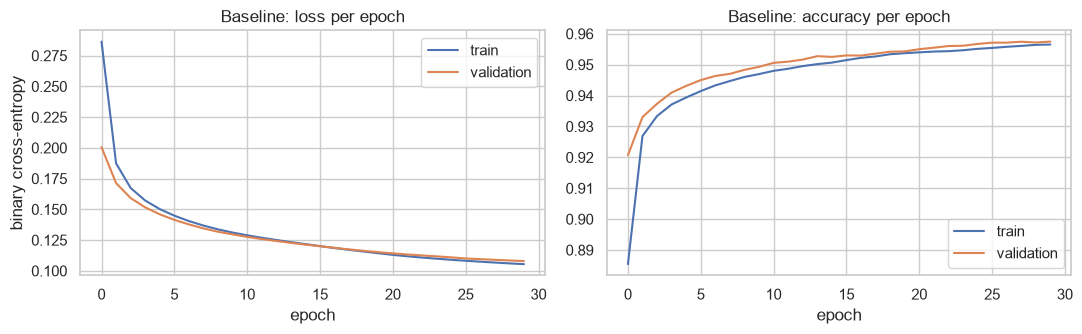

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(hist.history["loss"], label="train"); ax[0].plot(hist.history["val_loss"], label="validation"); ax[0].set(title="Baseline: loss per epoch", xlabel="epoch", ylabel="binary cross-entropy"); ax[0].legend()
ax[1].plot(hist.history["accuracy"], label="train"); ax[1].plot(hist.history["val_accuracy"], label="validation"); ax[1].set(title="Baseline: accuracy per epoch", xlabel="epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

**Figure 4.** Both losses fall quickly in the first 5 epochs and then slowly; the validation curve stays very close to the training curve, so the baseline does not over-fit. The curves are still going down at epoch 30 – a small network with one hidden layer learns slowly, which suggests trying more neurons and layers.

### 7.1 Hyperparameter experiments

Each experiment changes one thing compared to the configuration (64, 32) neurons, learning rate 0.001, batch 128, up to 30 epochs. Every model is scored on the test set.

In [15]:
def experiment(name, hidden=(64, 32), lr=0.001, batch_size=128, epochs=30):
    m = build(hidden, lr); h, t = train(m, epochs, batch_size)
    r = test_metrics(m); r.update({"epochs run": len(h.history["loss"]), "best val loss": min(h.history["val_loss"]), "time, s": t})
    return name, r, m, h

exp = []
for hidden in [(32,), (64, 32), (128, 64, 32)]:
    exp.append(experiment(f"hidden layers {hidden}", hidden=hidden))
pd.DataFrame({n: r for n, r, _, _ in exp}).T.round(4)

,Accuracy,Precision,Recall,F1,epochs run,best val loss,"time, s"
"hidden layers (32,)",0.9511,0.9583,0.9278,0.9428,30.0,0.1105,24.4855
"hidden layers (64, 32)",0.9574,0.9665,0.9343,0.9501,30.0,0.0966,26.6270
"hidden layers (128, 64, 32)",0.9572,0.9752,0.9251,0.9495,13.0,0.1002,13.6658


**Number of hidden layers and neurons.** One hidden layer of 32 neurons gives F1 ≈ 0.94; two layers (64, 32) improve it to ≈ 0.95 and reach a lower validation loss (≈ 0.097 vs 0.111). A third layer (128, 64, 32) gives the same quality (F1 ≈ 0.95) and converges in fewer epochs (13), but its validation loss is not better – the extra capacity is not needed for 27 inputs. **(64, 32) is the best size.**

In [16]:
exp = []
for lr in [0.0001, 0.001, 0.01]:
    exp.append(experiment(f"learning rate {lr}", lr=lr))
pd.DataFrame({n: r for n, r, _, _ in exp}).T.round(4)

,Accuracy,Precision,Recall,F1,epochs run,best val loss,"time, s"
learning rate 0.0001,0.9457,0.9512,0.9224,0.9366,30.0,0.1220,28.2832
learning rate 0.001,0.9568,0.9542,0.9460,0.9500,30.0,0.0961,27.5235
learning rate 0.01,0.9580,0.9692,0.9329,0.9507,17.0,0.0917,15.5715


**Learning rate.** With 0.0001 the steps are too small: after 30 epochs the loss is still about 0.122 and the model is the weakest (under-training). 0.001 (the Adam default) and 0.01 reach the same F1 ≈ 0.95; 0.01 converges in fewer epochs, but a large rate can jump over the minimum on other data, so 0.001 stays the safe choice.

In [17]:
exp = []
for bs in [32, 128, 512]:
    exp.append(experiment(f"batch size {bs}", batch_size=bs))
pd.DataFrame({n: r for n, r, _, _ in exp}).T.round(4)

,Accuracy,Precision,Recall,F1,epochs run,best val loss,"time, s"
batch size 32,0.9576,0.9735,0.9276,0.9500,25.0,0.0971,80.3328
batch size 128,0.9584,0.9649,0.9383,0.9514,27.0,0.0950,24.3710
batch size 512,0.9557,0.9677,0.9289,0.9479,30.0,0.1000,10.8175


**Batch size.** Batch 32 makes ≈ 2 600 weight updates per epoch – the most accurate gradient path, but the slowest (about 7 times longer than batch 512: 80 s vs 11 s). Batch 512 is the fastest but the loss is a little higher because fewer updates are made. Batch 128 is a good compromise: almost the same F1 as 32 at a fraction of the time.

In [18]:
exp = []
for ep in [5, 30, 100]:
    exp.append(experiment(f"max epochs {ep}", hidden=(64, 32), epochs=ep))
final_name, final_res, final_model, final_hist = exp[-1]
pd.DataFrame({n: r for n, r, _, _ in exp}).T.round(4)

,Accuracy,Precision,Recall,F1,epochs run,best val loss,"time, s"
max epochs 5,0.9514,0.9554,0.9316,0.9433,5.0,0.1118,5.2531
max epochs 30,0.9587,0.9618,0.9424,0.9520,30.0,0.0958,27.4663
max epochs 100,0.9575,0.9646,0.9365,0.9503,34.0,0.0977,31.2175


**Number of epochs.** 5 epochs are not enough (loss ≈ 0.112, F1 ≈ 0.94 – under-fitting). With up to 100 epochs early stopping ends training after 34 epochs anyway, because the validation loss stops improving; the training loss keeps going down, so more epochs would only give over-fitting. Early stopping is therefore the right way to choose the number of epochs.

**Final model:** 27 inputs → Dense 64 (ReLU) → Dense 32 (ReLU) → Dense 1 (Sigmoid); Adam, learning rate 0.001, batch 128, early stopping (the model from the last experiment).

## 8. Evaluation

In [19]:
logreg = LogisticRegression(max_iter=3000).fit(A_train, y_train)
p_lr = logreg.predict(A_test)
res["Logistic Regression (reference)"] = {"Accuracy": accuracy_score(y_test, p_lr), "Precision": precision_score(y_test, p_lr), "Recall": recall_score(y_test, p_lr), "F1": f1_score(y_test, p_lr)}
res["Final NN (64, 32)"] = {k: final_res[k] for k in ["Accuracy", "Precision", "Recall", "F1"]}
table = pd.DataFrame(res).T.round(4)
table["meets criteria"] = (table["Accuracy"] >= 0.90) & (table["Recall"] >= 0.90) & (table["F1"] >= 0.90)
table

,Accuracy,Precision,Recall,F1,meets criteria
Baseline NN (32),0.9512,0.9553,0.9312,0.9431,True
Logistic Regression (reference),0.8871,0.8716,0.8681,0.8698,False
"Final NN (64, 32)",0.9575,0.9646,0.9365,0.9503,True


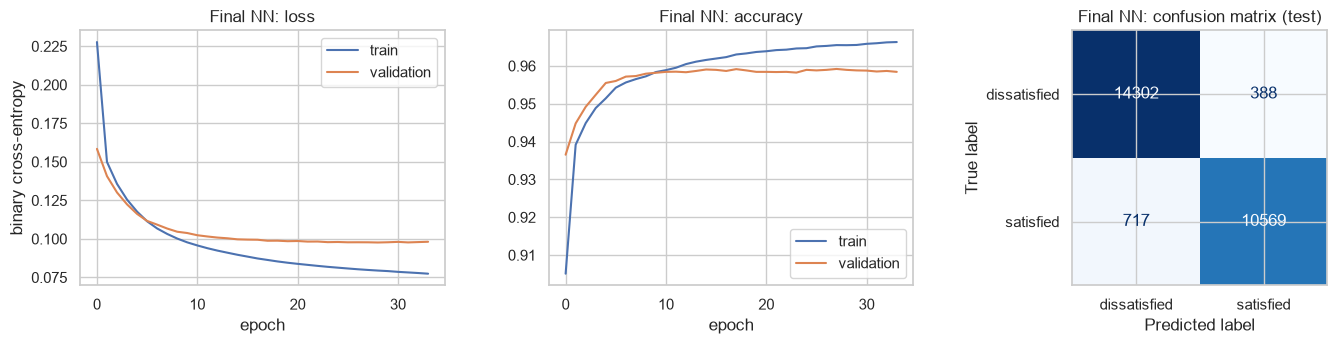

epochs trained: 34 | final train loss 0.077 | best validation loss 0.098


In [20]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].plot(final_hist.history["loss"], label="train"); ax[0].plot(final_hist.history["val_loss"], label="validation"); ax[0].set(title="Final NN: loss", xlabel="epoch", ylabel="binary cross-entropy"); ax[0].legend()
ax[1].plot(final_hist.history["accuracy"], label="train"); ax[1].plot(final_hist.history["val_accuracy"], label="validation"); ax[1].set(title="Final NN: accuracy", xlabel="epoch"); ax[1].legend()
p_nn = (final_model.predict(A_test, verbose=0) > 0.5).astype(int).ravel()
ConfusionMatrixDisplay(confusion_matrix(y_test, p_nn), display_labels=["dissatisfied", "satisfied"]).plot(ax=ax[2], cmap="Blues", colorbar=False); ax[2].set_title("Final NN: confusion matrix (test)")
plt.tight_layout(); plt.show()
print("epochs trained:", len(final_hist.history["loss"]), "| final train loss %.3f | best validation loss %.3f" % (final_hist.history["loss"][-1], min(final_hist.history["val_loss"])))

**Over-fitting or under-fitting?** The training loss keeps falling (to ≈ 0.077) while the validation loss flattens at ≈ 0.098 after about 10 epochs and then stays level – a small gap appears, which is the beginning of over-fitting, and early stopping stops the training exactly there (after 34 epochs). Train accuracy (≈ 0.97) and test accuracy (≈ 0.96) are close, so the model is neither under-fitted (as the 5-epoch or lr = 0.0001 versions were) nor seriously over-fitted.

**Results.** The final network reaches accuracy ≈ 0.958, precision ≈ 0.96, recall ≈ 0.94 and F1 ≈ 0.95 on 25 976 test passengers. Of 11 286 satisfied passengers about 10 600 are recognised, and only about 400 of 14 690 dissatisfied passengers are wrongly called satisfied. The reference logistic regression on the same inputs gives accuracy ≈ 0.887 and F1 ≈ 0.870 – the network adds 7–8 points, because satisfaction depends on **combinations** of ratings and passenger type (for example, online boarding matters for business travellers, wifi for economy), and a linear model cannot learn such interactions.

**Business criteria.** Accuracy ≈ 0.958 ≥ 0.90, recall ≈ 0.94 ≥ 0.90, F1 ≈ 0.95 ≥ 0.90 – all met. The logistic regression fails all three.

## 9. Conclusion

* **Data and preprocessing.** 129 880 airline passengers (Kaggle), 22 features, 43 % satisfied. 393 missing arrival delays filled with the departure delay, index columns removed, no duplicates or invalid values. Three features created (`avg_service`, `total_delay`, `n_zero_ratings`), categories one-hot encoded, numbers standardised on the training set only; 80 / 20 train / test split plus a validation set for early stopping.
* **Architecture and training.** Keras sequential network 27 → 64 (ReLU) → 32 (ReLU) → 1 (Sigmoid), binary cross-entropy loss, Adam optimizer, learning rate 0.001, batch 128, early stopping after 34 epochs. Loss went from about 0.74 (random weights) to about 0.08 on the training set; the first-layer weights changed on average by about 0.25.
* **Hyperparameters.** Two hidden layers beat one; a third adds nothing. Learning rate 0.0001 under-trains, 0.001 and 0.01 are equally good. Batch 128 balances accuracy and speed. Early stopping picks the number of epochs; 5 epochs are too few.
* **Results.** Final network: accuracy ≈ 0.958, F1 ≈ 0.95, recall ≈ 0.94 on the test set; logistic regression: accuracy ≈ 0.887, F1 ≈ 0.870. **All business criteria are met.** No serious over-fitting: train and validation curves stay close.
* **Improvements.** (1) Add dropout or L2 regularization and a learning-rate schedule to close the small train / validation gap; (2) analyse the network with SHAP or permutation importance to tell the airline exactly which services to improve for which passenger group; (3) collect real survey data with dates and routes and check the model on new months, because passenger expectations change over time.

## 10. References

Abadi, M., Barham, P., Chen, J., Chen, Z., Davis, A., Dean, J., Devin, M., Ghemawat, S., Irving, G., Isard, M., Kudlur, M., Levenberg, J., Monga, R., Moore, S., Murray, D. G., Steiner, B., Tucker, P., Vasudevan, V., Warden, P., … Zheng, X. (2016). TensorFlow: A system for large-scale machine learning. *Proceedings of the 12th USENIX Symposium on Operating Systems Design and Implementation (OSDI 16)*, 265–283.

Chollet, F. (2015). *Keras* [Computer software]. https://keras.io

Géron, A. (2019). *Hands-on machine learning with Scikit-Learn, Keras, and TensorFlow: Concepts, tools, and techniques to build intelligent systems* (2nd ed.). O'Reilly Media. (Chapters 10–11: introduction to artificial neural networks with Keras; training deep neural networks)

Kingma, D. P., & Ba, J. (2015). Adam: A method for stochastic optimization. *Proceedings of the 3rd International Conference on Learning Representations (ICLR)*. https://arxiv.org/abs/1412.6980

Klein, T. J. (2020). *Airline passenger satisfaction* [Data set]. Kaggle. https://www.kaggle.com/datasets/teejmahal20/airline-passenger-satisfaction

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.

Rumelhart, D. E., Hinton, G. E., & Williams, R. J. (1986). Learning representations by back-propagating errors. *Nature, 323*(6088), 533–536. https://doi.org/10.1038/323533a0